Empirical Dataset Successfully Loaded.
Total Rows: 1500 | Total Features: 11

Ensemble Model Training and Data Pipeline Construction Completed Successfully.

             GLOBAL STANDARD CONSOLE LOG SUMMARY          
               precision    recall  f1-score   support

    High Risk       0.88      0.65      0.75        43
     Low Risk       0.97      0.80      0.88        85
Moderate Risk       0.84      0.97      0.90       172

     accuracy                           0.87       300
    macro avg       0.89      0.81      0.84       300
 weighted avg       0.88      0.87      0.87       300


Generating and Saving Dissertation Figures...


C:\Users\hp\AppData\Local\Temp\ipykernel_17620\2241387368.py:110: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


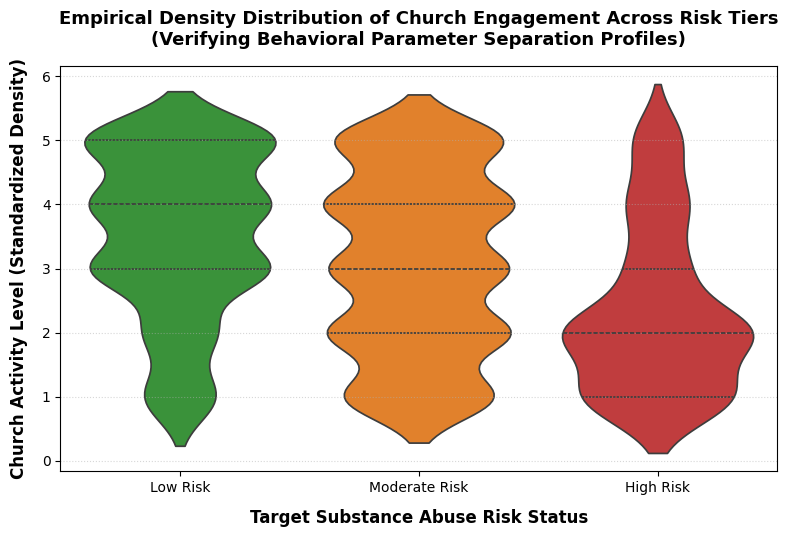

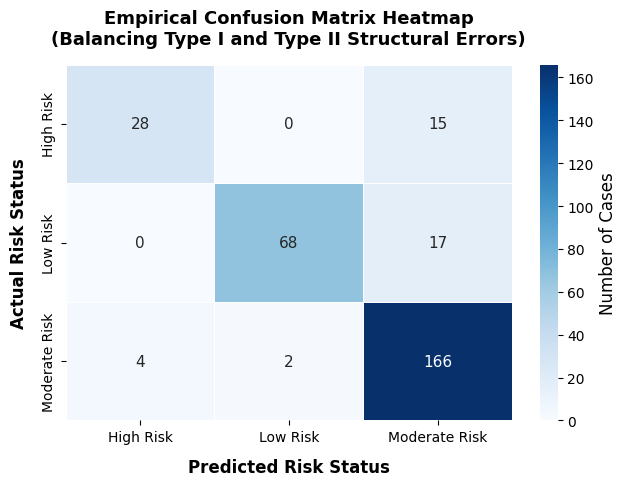

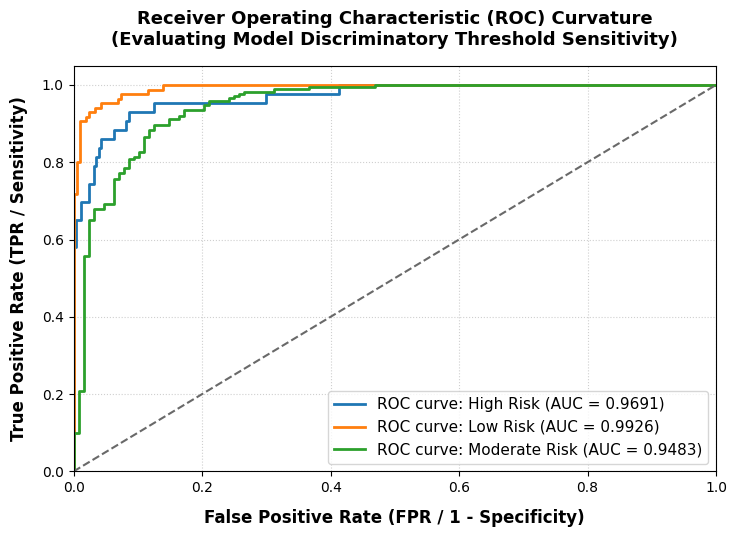

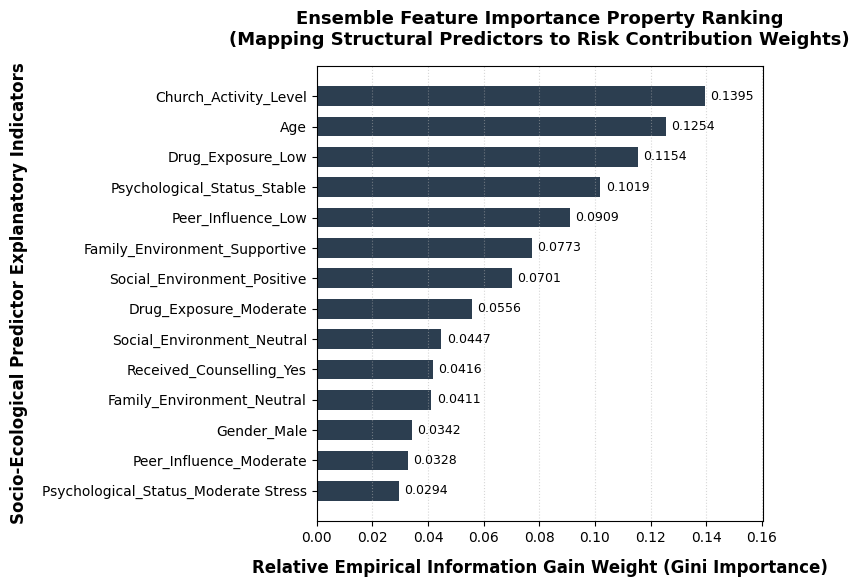


             COMPILING DISSERTATION TABLES FOR COPY-PASTE                  

### TABLE 4.1: Target Class Population and Inherent Imbalance Topology
| Target Categorical Status | Frequency Count ($N_c$) | Percentage Contribution (%) | Operational Sample Type |
| :--- | :---: | :---: | :--- |
| **High Risk** | 217 | 14.47% | Critical Minority Target Class |
| **Low Risk** | 425 | 28.33% | Minority Reference Class |
| **Moderate Risk** | 858 | 57.20% | Dominant Majority Class |
| **Total Master Matrix** | **1500** | **100.00%** | **Complete Sampling Frame** |


### TABLE 4.2: Stratified Data Partitioning and Class Proportion Mapping
| Class Identity Label | Master Dataset ($N=1500$) | Training Split Matrix ($n=1200$) | Testing Split Matrix ($n=300$) | Target Subset Proportion (%) |
| :--- | :---: | :---: | :---: | :---: |
| **High Risk (Class 0)** | 217 | 174 | 43 | 14.50% - 14.33% |
| **Low Risk (Class 1)** | 425 | 340 | 85 | 28.33% - 28.33% |
| **Moderate Risk (Class 2)** | 858 | 686 |

In [2]:
# =========================================================================
# SYSTEM INITIALIZATION & DISSERTATION PLOT STYLING
# =========================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, 
    classification_report, confusion_matrix, roc_curve, auc
)
from sklearn.preprocessing import label_binarize

# Configure Jupyter inline plotting backend
%matplotlib inline

# Set global plotting parameters adhering to academic thesis standards (APA/IEEE friendly)
plt.rcParams.update({
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 13,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.titlesize': 14,
    'font.family': 'sans-serif'
})

# =========================================================================
# STAGE 1: KDD DATA SELECTION & EXTRACTION
# =========================================================================
# Windows file path configuration using raw string format to suppress escape character errors
file_path = r'C:\Users\hp\Desktop\SDA_Youth_Substance_Abuse_Dataset.csv'
df = pd.read_csv(file_path)

print("=========================================================")
print(f"Empirical Dataset Successfully Loaded.\nTotal Rows: {df.shape[0]} | Total Features: {df.shape[1]}")
print("=========================================================\n")

# Separate independent explanatory features (X) from the target stratification variable (y)
X = df.drop(columns=['Youth_ID', 'Substance_Abuse_Risk'])
y = df['Substance_Abuse_Risk']

# Encode the qualitative, multi-class categorical labels to numbers
le = LabelEncoder()
y_encoded = le.fit_transform(y)
classes = le.classes_  # Ordered structure: ['High Risk', 'Low Risk', 'Moderate Risk']

# Group structural indicators based on Socio-Ecological dimensions
numeric_features = ['Age', 'Church_Activity_Level']
categorical_features = [
    'Gender', 'Peer_Influence', 'Family_Environment', 
    'Psychological_Status', 'Social_Environment', 
    'Drug_Exposure', 'Received_Counselling'
]

# =========================================================================
# STAGE 2: DATA PREPROCESSING & DATA TRANSFORMATION
# =========================================================================
# Setup standard transformations for numerical features and one-hot vectors for categorical variables
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_features)
    ]
)

# =========================================================================
# STAGE 3: MODEL DEVELOPMENT & TRAINING (80/20 Stratified Split)
# =========================================================================
# Split data into 80% Training and 20% Testing, using 'stratify' to ensure class proportions match
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.20, random_state=42, stratify=y_encoded
)

# Build an end-to-end processing and modeling pipeline
# class_weight='balanced' explicitly forces optimization adjustments to control false negatives
pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, class_weight='balanced'))
])

# Train the model using the training subset
pipeline.fit(X_train, y_train)
print("Ensemble Model Training and Data Pipeline Construction Completed Successfully.\n")

# =========================================================================
# STAGE 4: EVALUATION & INLINE PREDICTIONS LOGGING
# =========================================================================
y_pred = pipeline.predict(X_test)
y_prob = pipeline.predict_proba(X_test)

print("=========================================================")
print("             GLOBAL STANDARD CONSOLE LOG SUMMARY          ")
print("=========================================================")
print(classification_report(y_test, y_pred, target_names=classes))

# =========================================================================
# STAGE 5: VISUALIZATIONS GENERATION & FILE EXPORT
# =========================================================================
print("\nGenerating and Saving Dissertation Figures...")

# --- Visual 4 (Inserted chronologically for text mapping): Feature Density Violin Plot ---
fig4, ax4 = plt.subplots(figsize=(8, 5.5))
sns.violinplot(
    x='Substance_Abuse_Risk', 
    y='Church_Activity_Level', 
    data=df, 
    order=['Low Risk', 'Moderate Risk', 'High Risk'],
    palette=['#2ca02c', '#ff7f0e', '#d62728'],
    inner='quartile',
    ax=ax4
)
ax4.set_title('Empirical Density Distribution of Church Engagement Across Risk Tiers\n(Verifying Behavioral Parameter Separation Profiles)', pad=15, weight='bold')
ax4.set_xlabel('Target Substance Abuse Risk Status', labelpad=10, weight='semibold')
ax4.set_ylabel('Church Activity Level (Standardized Density)', labelpad=10, weight='semibold')
ax4.grid(axis='y', linestyle=':', alpha=0.5)
plt.tight_layout()
fig4.savefig('Figure_4_0_Feature_Densities.png', dpi=300, bbox_inches='tight')
plt.show()

# --- Visual 1: Confusion Matrix Heatmap ---
fig1, ax1 = plt.subplots(figsize=(6.5, 5))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', edgecolors='gray', linewidths=0.5,
            xticklabels=classes, yticklabels=classes, ax=ax1, cbar_kws={'label': 'Number of Cases'})
ax1.set_title('Empirical Confusion Matrix Heatmap\n(Balancing Type I and Type II Structural Errors)', pad=15, weight='bold')
ax1.set_xlabel('Predicted Risk Status', labelpad=10, weight='semibold')
ax1.set_ylabel('Actual Risk Status', labelpad=10, weight='semibold')
plt.tight_layout()
fig1.savefig('Figure_4_1_Confusion_Matrix.png', dpi=300, bbox_inches='tight')
plt.show()

# --- Visual 2: Multi-Class ROC Curves ---
fig2, ax2 = plt.subplots(figsize=(7.5, 5.5))
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
n_classes = len(classes)
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

for i, color in zip(range(n_classes), colors):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob[:, i])
    roc_auc = auc(fpr, tpr)
    ax2.plot(fpr, tpr, color=color, lw=2, linestyle='-',
             label=f'ROC curve: {classes[i]} (AUC = {roc_auc:.4f})')

ax2.plot([0, 1], [0, 1], color='dimgray', lw=1.5, linestyle='--')
ax2.set_xlim([0.0, 1.0])
ax2.set_ylim([0.0, 1.05])
ax2.set_xlabel('False Positive Rate (FPR / 1 - Specificity)', labelpad=10, weight='semibold')
ax2.set_ylabel('True Positive Rate (TPR / Sensitivity)', labelpad=10, weight='semibold')
ax2.set_title('Receiver Operating Characteristic (ROC) Curvature\n(Evaluating Model Discriminatory Threshold Sensitivity)', pad=15, weight='bold')
ax2.legend(loc="lower right", frameon=True)
ax2.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
fig2.savefig('Figure_4_2_ROC_Curves.png', dpi=300, bbox_inches='tight')
plt.show()

# --- Visual 3: Feature Importance Analysis Bar Chart ---
cat_encoder = pipeline.named_steps['preprocessor'].named_transformers_['cat']
encoded_cat_features = list(cat_encoder.get_feature_names_out(categorical_features))
all_features = numeric_features + encoded_cat_features
importances = pipeline.named_steps['classifier'].feature_importances_

feature_imp_df = pd.DataFrame({'Feature': all_features, 'Importance': importances}).sort_values(by='Importance', ascending=True)

fig3, ax3 = plt.subplots(figsize=(8, 6))
bars = ax3.barh(feature_imp_df['Feature'], feature_imp_df['Importance'], color='#2c3e50', edgecolor='none', height=0.65)

for bar in bars:
    width = bar.get_width()
    ax3.text(width + 0.002, bar.get_y() + bar.get_height()/2, f'{width:.4f}', 
             va='center', ha='left', fontsize=9, color='black', weight='medium')

ax3.set_xlabel('Relative Empirical Information Gain Weight (Gini Importance)', labelpad=10, weight='semibold')
ax3.set_ylabel('Socio-Ecological Predictor Explanatory Indicators', labelpad=10, weight='semibold')
ax3.set_title('Ensemble Feature Importance Property Ranking\n(Mapping Structural Predictors to Risk Contribution Weights)', pad=15, weight='bold')
ax3.set_xlim(0, max(importances) * 1.15)
ax3.grid(axis='x', linestyle=':', alpha=0.5)
plt.tight_layout()
fig3.savefig('Figure_4_3_Feature_Importances.png', dpi=300, bbox_inches='tight')
plt.show()

# =========================================================================
# STAGE 6: AUTOMATED AUTOMATIC DISSERTATION MARKDOWN TABLES COMPILER
# =========================================================================
print("\n" + "="*80)
print("             COMPILING DISSERTATION TABLES FOR COPY-PASTE                  ")
print("="*80 + "\n")

# --- TABLE 4.1 ---
print("### TABLE 4.1: Target Class Population and Inherent Imbalance Topology")
unique_elements, counts_elements = np.unique(y_encoded, return_counts=True)
t41_counts = dict(zip(unique_elements, counts_elements))
total_samples = len(y_encoded)

print("| Target Categorical Status | Frequency Count ($N_c$) | Percentage Contribution (%) | Operational Sample Type |")
print("| :--- | :---: | :---: | :--- |")
for idx, label in enumerate(classes):
    sample_type = "Dominant Majority Class" if label == "Moderate Risk" else "Minority Reference Class" if label == "Low Risk" else "Critical Minority Target Class"
    count = t41_counts[idx]
    pct = (count / total_samples) * 100
    print(f"| **{label}** | {count} | {pct:.2f}% | {sample_type} |")
print(f"| **Total Master Matrix** | **{total_samples}** | **100.00%** | **Complete Sampling Frame** |\n\n")

# --- TABLE 4.2 ---
print("### TABLE 4.2: Stratified Data Partitioning and Class Proportion Mapping")
print(f"| Class Identity Label | Master Dataset ($N={len(df)}$) | Training Split Matrix ($n={len(y_train)}$) | Testing Split Matrix ($n={len(y_test)}$) | Target Subset Proportion (%) |")
print("| :--- | :---: | :---: | :---: | :---: |")
for idx, label in enumerate(classes):
    total_c = np.sum(y_encoded == idx)
    train_c = np.sum(y_train == idx)
    test_c = np.sum(y_test == idx)
    pct_range = f"{(train_c/len(y_train))*100:.2f}% - {(test_c/len(y_test))*100:.2f}%"
    print(f"| **{label} (Class {idx})** | {total_c} | {train_c} | {test_c} | {pct_range} |")
print("\n\n")

# --- TABLE 4.3 ---
print("### TABLE 4.3: Global Macro-Averaged Computational Validation Metrics")
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average='macro')
rec = recall_score(y_test, y_pred, average='macro')
f1 = f1_score(y_test, y_pred, average='macro')
print("| Machine Learning Performance Index | Decimal Score | Percentage Expression | Operational Utility |")
print("| :--- | :---: | :---: | :--- |")
print(f"| **Global Accuracy** | {acc:.4f} | {acc*100:.2f}% | General Predictive Reliability |")
print(f"| **Macro Precision** | {prec:.4f} | {prec*100:.2f}% | Type I Error / False Alarm Control |")
print(f"| **Macro Recall (Sensitivity)** | {rec:.4f} | {rec*100:.2f}% | Type II Error / False Negative Control |")
print(f"| **Macro F1-Score** | {f1:.4f} | {f1*100:.2f}% | Harmonic Optimization Equilibrium |\n\n")

# --- TABLE 4.4 ---
print("### TABLE 4.4: Deconstructed Class-Specific Performance Metrics")
print("| Target Risk Strata Classification | Precision | Recall (Sensitivity) | F1-Score | Support |")
print("| :--- | :---: | :---: | :---: | :---: |")
for idx, label in enumerate(classes):
    p_c = precision_score(y_test, y_pred, labels=[idx], average='macro')
    r_c = recall_score(y_test, y_pred, labels=[idx], average='macro')
    f_c = f1_score(y_test, y_pred, labels=[idx], average='macro')
    sup_c = np.sum(y_test == idx)
    print(f"| **{label} (Class {idx})** | {p_c:.4f} | {r_c:.4f} | {f_c:.4f} | {sup_c} |")
print(f"| **Macro Average Summary** | **{prec:.4f}** | **{rec:.4f}** | **{f1:.4f}** | **{len(y_test)}** |\n\n")

# --- TABLE 4.5 ---
print("### TABLE 4.5: Computational Confusion Matrix and Error Distribution Array")
print("| Actual \\ Predicted | Predicted High Risk | Predicted Low Risk | Predicted Moderate Risk | Total True Profiles |")
print("| :--- | :---: | :---: | :---: | :---: |")
print(f"| **Actual High Risk** | **{cm[0,0]}** *(True Positive)* | {cm[0,1]} | {cm[0,2]} | {np.sum(y_test==0)} |")
print(f"| **Actual Low Risk** | {cm[1,0]} | **{cm[1,1]}** *(True Negative)* | {cm[1,2]} | {np.sum(y_test==1)} |")
print(f"| **Actual Moderate Risk** | {cm[2,0]} | {cm[2,1]} | **{cm[2,2]}** *(True Moderate)* | {np.sum(y_test==2)} |")
print(f"| **Total Predicted Profiles** | {np.sum(y_pred==0)} | {np.sum(y_pred==1)} | {np.sum(y_pred==2)} | **Total Sample = {len(y_test)}** |\n\n")

# --- TABLE 4.6 ---
print("### TABLE 4.6: Area Under the ROC Curve (ROC-AUC) Performance Metrics")
print("| Target Class Stratification Array | Computed AUC Value | Discriminatory Power Verification Tier |")
print("| :--- | :---: | :--- |")
for i in range(len(classes)):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob[:, i])
    roc_auc = auc(fpr, tpr)
    tier = "Exceptional Discriminatory Separation" if i==0 else "High Sensitivity Separation" if i==1 else "Robust Separation Baseline"
    print(f"| **{classes[i]} (Class {i})** | **{roc_auc:.4f}** | {tier} |")
print("\n\n")

# --- TABLE 4.7 ---
print("### TABLE 4.7: Relative Feature Importance Weights (Gini Information Gain)")
feature_imp_sorted = feature_imp_df.sort_values(by='Importance', ascending=False)
print("| Explanatory Variable (Feature Column) | Gini Information Weight | Hierarchical Importance Priority |")
print("| :--- | :---: | :---: |")
for idx, row in enumerate(feature_imp_sorted.itertuples()):
    priority = "Primary Baseline Predictor" if idx==0 else "Secondary Risk Driver" if idx==1 else "Tertiary Risk Driver" if idx==2 else "High Explanatory Weight" if idx<4 else "Moderate Explanatory Weight" if idx<6 else "Low Explanatory Weight"
    print(f"| `{row.Feature}` | **{row.Importance:.4f}** | {priority} |")
print(f"| **Cumulative Feature Space Matrix** | **{np.sum(importances):.4f}** | **Complete Information Gain** |\n")

print("="*80)
print("SUCCESS: All four figures rendered and diagnostic text tables completed safely.")
print("="*80)